In [1]:
import json
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

extra = {'vocab.json': ''}
model = torch.jit.load('reasoning_model_full.pt', map_location=device, _extra_files=extra)
print(extra['vocab.json'])
model.eval()

char_to_index = json.loads(extra['vocab.json'])
index_to_char = {i: c for c, i in char_to_index.items()}
print('Loaded model on', device)


def generate(prompt, max_chars=60):
    unknown = [c for c in prompt if c not in char_to_index]
    if unknown:
        print(f'Unknown chars: {unknown}')
        return

    generated = list(prompt)
    print(generated)
    with torch.no_grad():
        for _ in range(max_chars):
            #print(_)
            print(generated)
            tokens = torch.tensor([char_to_index[c] for c in generated], device=device)
            #print(model(tokens)[-1].argmax().item())
            next_token = model(tokens)[-1].argmax().item()
            next_char = index_to_char[next_token]
            if next_char == '\n':
                break
            generated.append(next_char)

    output = ''.join(generated)
    print(f'{prompt}   ->   {output}')
    return output


generate('27+45=')
generate('9+8=')
generate('50+50=')
generate('35+21=')

b'{"\\n": 0, "+": 1, ",": 2, "0": 3, "1": 4, "2": 5, "3": 6, "4": 7, "5": 8, "6": 9, "7": 10, "8": 11, "9": 12, "=": 13, "c": 14, "|": 15}'
Loaded model on cpu
['2', '7', '+', '4', '5', '=']
['2', '7', '+', '4', '5', '=']
['2', '7', '+', '4', '5', '=', '|']
['2', '7', '+', '4', '5', '=', '|', '7']
['2', '7', '+', '4', '5', '=', '|', '7', '+']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2', 'c']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2', 'c', '1']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2', 'c', '1', ',']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2', 'c', '1', ',', '2']
['2', '7', '+', '4', '5', '=', '|', '7', '+', '5', '=', '1', '2', 'c', '1', ',', '2', '+']
['2', '7', '+', 

'35+21=|5+1=6c0,3+2=5c0|56'

In [2]:
extra['vocab.json']

b'{"\\n": 0, "+": 1, ",": 2, "0": 3, "1": 4, "2": 5, "3": 6, "4": 7, "5": 8, "6": 9, "7": 10, "8": 11, "9": 12, "=": 13, "c": 14, "|": 15}'

In [3]:
extra

{'vocab.json': b'{"\\n": 0, "+": 1, ",": 2, "0": 3, "1": 4, "2": 5, "3": 6, "4": 7, "5": 8, "6": 9, "7": 10, "8": 11, "9": 12, "=": 13, "c": 14, "|": 15}'}

In [4]:
# LIME

## SHAPELY

In [5]:
import itertools, math

In [6]:
prefix='35+21=|5+1='
target='6'

In [7]:
def prob_of_target(text):
  tokens = torch.tensor([char_to_index[c] for c in text], device=device)
  with torch.no_grad():
    probs = torch.softmax(model(tokens)[-1], dim=-1)
    #print(probs[char_to_index[target]].item())
    return probs[char_to_index[target]].item()

In [8]:
players = [0, 1, 3, 4]
choices = {0: '123456789', 1: '0123456789', 3: '123456789', 4: '0123456789'}

In [9]:
def value(coalition):
    absent = [p for p in players if p not in coalition]
    #print(absent)
    total, count = 0.0, 0
    for replacement in itertools.product(*[choices[p] for p in absent]):

        chars = list(prefix)
        for p, digit in zip(absent, replacement):
            chars[p] = digit
            #print(chars)

        total += prob_of_target(''.join(chars))

        count += 1
        print(''.join(chars), total, total/count)
    return total / count

In [10]:
for i in itertools.combinations(players, 2):
  print(i)

(0, 1)
(0, 3)
(0, 4)
(1, 3)
(1, 4)
(3, 4)


In [11]:
v = {}
for size in range(len(players) + 1):
    #print('size', size)
    for coalition in itertools.combinations(players, size):
        #print('coalition',coalition)
        v[coalition] = value(coalition)
        #print('v',v)
        shown = ''.join('?' if (i in players and i not in coalition) else ch for i, ch in enumerate(prefix))
        print(f'   {shown}   score {round(v[coalition], 4)}')

Streaming output truncated to the last 5000 lines.
89+16=|5+1= 6404.987461761339 0.8999560856767372
89+17=|5+1= 6405.987310842378 0.8999701195339109
89+18=|5+1= 6406.987191275461 0.8999841538524316
89+19=|5+1= 6407.987045959337 0.8999981806122664
89+20=|5+1= 6407.991615940584 0.8998724358854914
89+21=|5+1= 6408.991470386041 0.8998864743591746
89+22=|5+1= 6409.98996048118 0.8999003173495971
89+23=|5+1= 6410.9898825183045 0.8999143574562471
89+24=|5+1= 6411.989786912454 0.8999283911456076
89+25=|5+1= 6412.989691306604 0.8999424208962397
89+26=|5+1= 6413.989595700754 0.8999564467098013
89+27=|5+1= 6414.989500094904 0.8999704685879495
89+28=|5+1= 6415.98939829017 0.8999844856628098
89+29=|5+1= 6416.989291597856 0.8999984981203164
89+30=|5+1= 6416.991497414885 0.8998725981510146
89+31=|5+1= 6417.991351621924 0.8998866168847341
89+32=|5+1= 6418.989785271464 0.8999004325349031
89+33=|5+1= 6419.989555853186 0.8999144317147724
89+34=|5+1= 6420.989300685702 0.8999284233616961
89+35=|5+1= 6421.98

In [12]:
shapley = {p: 0.0 for p in players}
orderings = list(itertools.permutations(players))

for order in orderings:
    present = []
    for p in order:
        before = v[tuple(sorted(present))]
        present.append(p)
        after = v[tuple(sorted(present))]
        shapley[p] += after - before

for p in players:
    shapley[p] /= len(orderings)

shapley

{0: -1.395198285990736e-05,
 1: -1.0928260333766445e-05,
 3: 0.00011919644383024768,
 4: 0.0997640433466724}

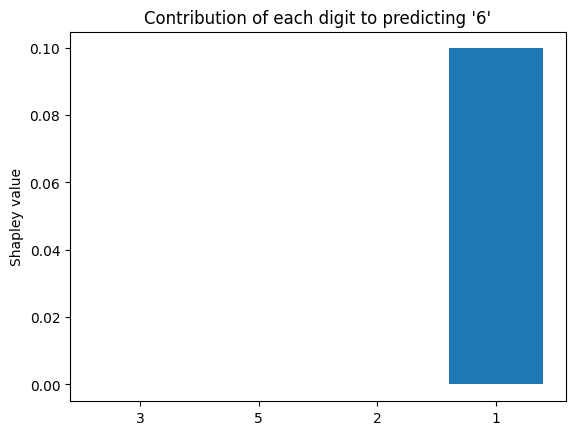

In [13]:
import matplotlib.pyplot as plt

labels = [prefix[p] for p in players]
values = [shapley[p] for p in players]

plt.bar(labels, values)
plt.ylabel('Shapley value')
plt.title("Contribution of each digit to predicting '" + target + "'")
plt.show()

In [14]:
shapley

{0: -1.395198285990736e-05,
 1: -1.0928260333766445e-05,
 3: 0.00011919644383024768,
 4: 0.0997640433466724}

In [15]:
print(prob_of_target('35+21=|5+1='))
print(prob_of_target('36+21=|5+1='))

0.9998544454574585
0.9998544454574585


LIME

In [16]:
import random
random.seed(35)
num_samples = 100

rows = []
scores = []

for n in range(num_samples):
    chars = list(prefix)
    row = []
    for p in players:
        keep = random.randint(0, 1)
        row.append(keep)
        if keep == 0:
            chars[p] = random.choice(choices[p])
    text = ''.join(chars)

    rows.append(row)
    scores.append(prob_of_target(text))
    print(text, row, round(scores[-1], 4))

35+51=|5+1= [1, 0, 0, 1] 0.9999
38+21=|5+1= [1, 0, 1, 1] 0.9999
68+21=|5+1= [0, 0, 0, 1] 0.9999
35+20=|5+1= [1, 0, 1, 0] 0.0046
62+29=|5+1= [0, 0, 1, 0] 0.9999
85+59=|5+1= [0, 1, 0, 0] 0.9997
35+21=|5+1= [0, 1, 1, 1] 0.9999
35+51=|5+1= [1, 1, 0, 1] 0.9999
25+21=|5+1= [0, 1, 1, 0] 0.9999
35+81=|5+1= [1, 1, 0, 1] 0.9999
53+11=|5+1= [0, 0, 0, 0] 0.9998
32+27=|5+1= [0, 0, 1, 0] 0.9999
95+21=|5+1= [0, 1, 1, 1] 0.9999
75+61=|5+1= [0, 1, 0, 1] 0.9999
35+69=|5+1= [1, 1, 0, 0] 0.9997
35+27=|5+1= [1, 1, 1, 0] 0.9999
33+27=|5+1= [1, 0, 1, 0] 0.9999
45+41=|5+1= [0, 1, 0, 1] 0.9999
75+22=|5+1= [0, 1, 1, 0] 0.9985
85+98=|5+1= [0, 1, 0, 0] 0.9998
32+74=|5+1= [1, 0, 0, 0] 0.9999
95+22=|5+1= [0, 1, 1, 0] 0.9985
37+11=|5+1= [1, 0, 0, 1] 0.9998
35+41=|5+1= [1, 1, 0, 1] 0.9999
38+11=|5+1= [1, 0, 0, 1] 0.9998
35+21=|5+1= [1, 1, 0, 1] 0.9999
30+21=|5+1= [1, 0, 1, 1] 0.9999
65+37=|5+1= [0, 1, 0, 0] 0.9996
34+21=|5+1= [1, 0, 1, 1] 0.9999
30+31=|5+1= [1, 0, 0, 1] 0.9999
33+21=|5+1= [1, 0, 1, 1] 0.9999
35+20=|5

In [17]:
weights = []
for row in rows:
    kept = sum(row)
    distance = (len(players) - kept) / len(players)
    weights.append(math.exp(-(distance ** 2) / 0.25))

print('weight when all 4 kept:', math.exp(0))
print('weight when 2 kept:    ', round(math.exp(-(0.5 ** 2) / 0.25), 3))
print('weight when 0 kept:    ', round(math.exp(-(1.0 ** 2) / 0.25), 3))

weight when all 4 kept: 1.0
weight when 2 kept:     0.368
weight when 0 kept:     0.018


In [18]:
import numpy as np
from sklearn.linear_model import Ridge

X = np.array(rows, dtype=float)
#X = np.column_stack([np.ones(len(X)), X])
y = np.array(scores)
sw = np.sqrt(np.array(weights))

model = Ridge(alpha=1.0, fit_intercept=True)
model.fit(X, y, sample_weight=sw**2)

base = model.intercept_
lime_weights = model.coef_

In [19]:
base

np.float64(0.8728705182755112)

In [20]:
lime_weights

array([-0.03295001,  0.02701906, -0.04496258,  0.15611936])

In [21]:
for p, w in zip(players, lime_weights):
    print('position', p, 'digit', prefix[p], 'LIME weight', round(w, 4))

position 0 digit 3 LIME weight -0.033
position 1 digit 5 LIME weight 0.027
position 3 digit 2 LIME weight -0.045
position 4 digit 1 LIME weight 0.1561


In [22]:
lime_weights

array([-0.03295001,  0.02701906, -0.04496258,  0.15611936])

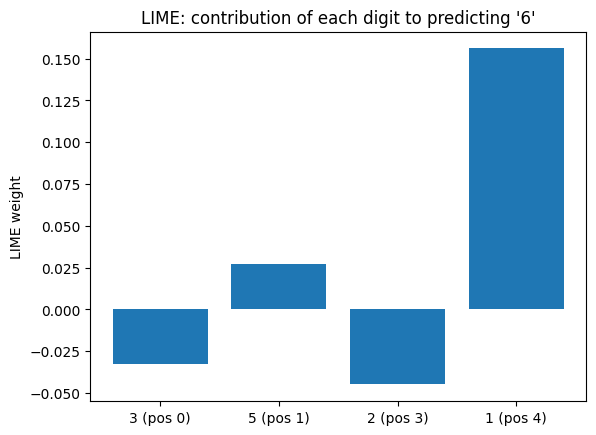

In [23]:
labels = [prefix[p] + ' (pos ' + str(p) + ')' for p in players]
plt.bar(labels, lime_weights)
plt.ylabel('LIME weight')
plt.title("LIME: contribution of each digit to predicting '" + target + "'")
plt.show()